In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df_fraud = pd.read_csv(url)

print(f"Toplam Satır Sayısı: {df_fraud.shape[0]}")
print(f"Toplam Sütun Sayısı: {df_fraud.shape[1]}")

df_fraud.head()

Toplam Satır Sayısı: 284807
Toplam Sütun Sayısı: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


gerçek insanların kredi kartı harcamaları olduğu için PCA ile veri şifrelemiş.

Normal İşlemler (0): 284315
Dolandırıcılık (1): 492


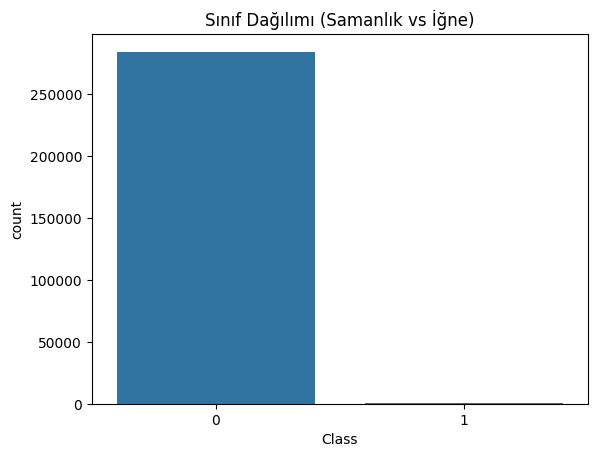

In [2]:
counts = df_fraud['Class'].value_counts()
print("Normal İşlemler (0):", counts[0])
print("Dolandırıcılık (1):", counts[1])

sns.countplot(x='Class', data=df_fraud)
plt.title('Sınıf Dağılımı (Samanlık vs İğne)')
plt.show()

Sınıf Dengesizliği

Veri seti çok dengesiz (Fraud oranı %0.17). Modeli eğitmek için SMOTE ile sentetik veri ürettim, yoksa model her şeye 'temiz' der.

In [3]:
import joblib
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, classification_report, precision_recall_curve
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_fraud.drop(columns=["Class", "Time"])
y = df_fraud["Class"]

# 60 / 20 / 20: train / validation (threshold seçimi) / test (son rapor)
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=42)

pipeline = Pipeline([
    ("prep", ColumnTransformer([("amount", StandardScaler(), ["Amount"])], remainder="passthrough")),
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)),
])

print("Model eğitiliyor, lütfen bekleyin...")
pipeline.fit(X_train, y_train)
print("Eğitim tamamlandı!")

# Threshold: validation setinde F1'i maksimize eden değer
val_proba = pipeline.predict_proba(X_val)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_val, val_proba)
f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
threshold = float(thresholds[np.argmax(f1)])

# Son değerlendirme: test seti
test_proba = pipeline.predict_proba(X_test)[:, 1]
y_pred = (test_proba >= threshold).astype(int)

print(f"\nSeçilen threshold: {threshold:.3f}")
print(f"Test PR-AUC: {average_precision_score(y_test, test_proba):.4f}")
print("\n--- DOLANDIRICILIK TESPİT RAPORU ---")
print(classification_report(y_test, y_pred, digits=3))

joblib.dump(
    {"pipeline": pipeline, "threshold": threshold, "features": list(X.columns)},
    "fraud_pipeline.joblib",
    compress=3,
)
print("Pipeline kaydedildi: fraud_pipeline.joblib")

Model eğitiliyor, lütfen bekleyin...
Eğitim tamamlandı!

Seçilen threshold: 0.600
Test PR-AUC: 0.8613

--- DOLANDIRICILIK TESPİT RAPORU ---
              precision    recall  f1-score   support

           0      1.000     1.000     1.000     56864
           1      0.890     0.827     0.857        98

    accuracy                          1.000     56962
   macro avg      0.945     0.913     0.928     56962
weighted avg      1.000     1.000     1.000     56962

Pipeline kaydedildi: fraud_pipeline.joblib


Veri aşırı dengesiz olduğu için accuracy yanıltıcıdır. Ana metrikler olarak PR-AUC (0.861), precision (0.890) ve recall (0.827) kullandım. Karar eşiğini (0.60) test setinde değil, validation setinde F1'i maksimize ederek seçtim. Böylece test sonuçları şişmiyor.

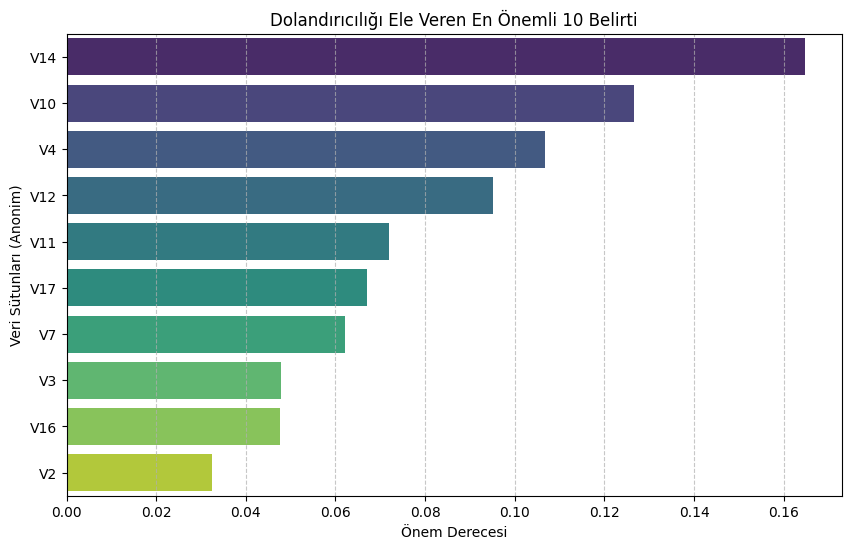

In [4]:
importances = pipeline.named_steps["model"].feature_importances_
feature_names = pipeline.named_steps["prep"].get_feature_names_out()
feature_names = [name.split("__")[-1] for name in feature_names]

feature_importance_df = (
    pd.DataFrame({"Özellik": feature_names, "Önem": importances})
    .sort_values(by="Önem", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
sns.barplot(x="Önem", y="Özellik", data=feature_importance_df, hue="Özellik", palette="viridis", legend=False)
plt.title("Dolandırıcılığı Ele Veren En Önemli 10 Belirti")
plt.xlabel("Önem Derecesi")
plt.ylabel("Veri Sütunları (Anonim)")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.show()

In [5]:
art = joblib.load("fraud_pipeline.joblib")

yeni_islem_df = pd.DataFrame(np.random.randn(1, 29), columns=art["features"])
prob = art["pipeline"].predict_proba(yeni_islem_df)[0, 1]

print(f"Üretilen Veri Şekli: {yeni_islem_df.shape}")
print(f"İşlemin Dolandırıcılık Olasılığı: %{prob*100:.2f}")
print(f"Model Kararı: {'FRAUD' if prob >= art['threshold'] else 'TEMİZ'}")

Üretilen Veri Şekli: (1, 29)
İşlemin Dolandırıcılık Olasılığı: %2.00
Model Kararı: TEMİZ


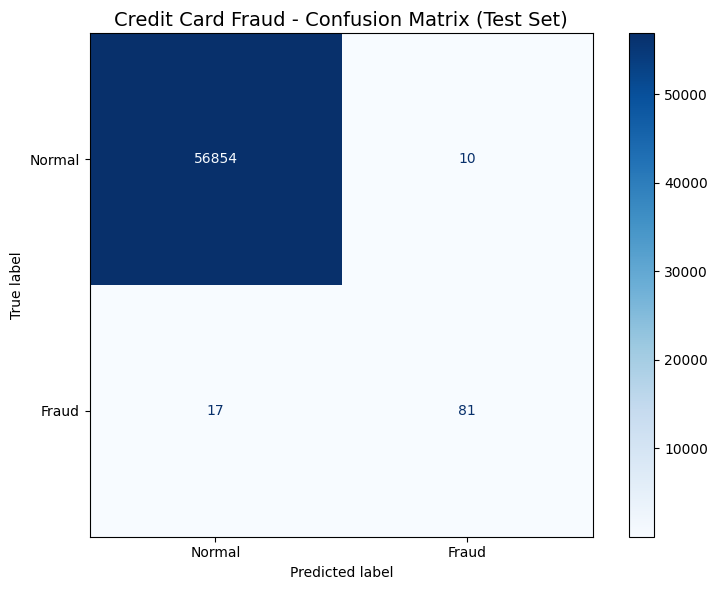

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Fraud"])

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title("Credit Card Fraud - Confusion Matrix (Test Set)", fontsize=14)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

In [7]:
   import sklearn, imblearn, pandas, joblib, numpy
   for m in (sklearn, imblearn, pandas, joblib, numpy): print(m.__name__, m.__version__)

sklearn 1.6.1
imblearn 0.14.2
pandas 2.2.3
joblib 1.6.0
numpy 2.1.3
